# W1D5 – Simple Data Visualisation

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style='whitegrid')

In [8]:
DATA_PATH = Path.cwd().parent / "data" / "states.csv"

print("CSV path:", DATA_PATH)
print("File exists:", DATA_PATH.exists())


CSV path: c:\Users\asus tuf a15\Desktop\Cynaris\cynaris-internship-Satish-Malladad\weekely-Activities\W1D5\data\states.csv
File exists: True


## 1. Load the dataset

In [10]:
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", df.shape)


Dataset loaded successfully!
Shape: (21675, 7)


In [11]:
df.head()

,Date,State,Confirmed,Recovered,Deceased,Other,Tested
0,2020-01-30,Kerala,1,0,0,0,NaN
1,2020-01-30,India,1,0,0,0,NaN
2,2020-02-02,Kerala,2,0,0,0,NaN
3,2020-02-02,India,2,0,0,0,NaN
4,2020-02-03,Kerala,3,0,0,0,NaN


## 2. Explore the data

In [12]:
df.info()
print('\nMissing values:')
display(df.isnull().sum())
print('\nSummary:')
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 21675 entries, 0 to 21674
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       21675 non-null  str    
 1   State      21675 non-null  str    
 2   Confirmed  21675 non-null  int64  
 3   Recovered  21675 non-null  int64  
 4   Deceased   21675 non-null  int64  
 5   Other      21675 non-null  int64  
 6   Tested     20912 non-null  float64
dtypes: float64(1), int64(4), str(2)
memory usage: 1.6 MB

Missing values:


Date           0
State          0
Confirmed      0
Recovered      0
Deceased       0
Other          0
Tested       763
dtype: int64


Summary:


,Confirmed,Recovered,Deceased,Other,Tested
count,2.167500e+04,2.167500e+04,21675.000000,21675.000000,2.091200e+04
mean,7.555970e+05,7.124357e+05,10139.065836,281.688028,1.260827e+07
std,3.094074e+06,2.962147e+06,41461.658802,1338.299441,4.843699e+07
min,0.000000e+00,0.000000e+00,0.000000,-1.000000,5.800000e+01
25%,6.745500e+03,4.966500e+03,56.000000,0.000000,1.861295e+05
50%,6.701600e+04,5.882300e+04,850.000000,0.000000,1.184390e+06
75%,4.799305e+05,4.012895e+05,5358.000000,4.000000,9.974060e+06
max,3.428561e+07,3.366134e+07,458470.000000,13197.000000,6.092013e+08


## 3. Histogram – distribution of the first numerical column

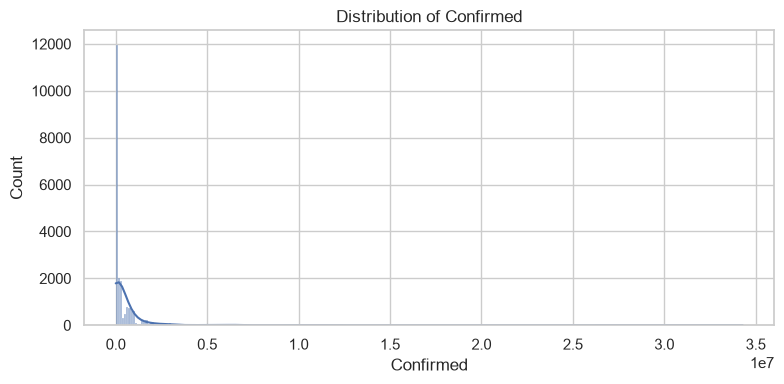

In [13]:
numeric_cols = df.select_dtypes(include='number').columns
if len(numeric_cols):
    col = numeric_cols[0]
    plt.figure(figsize=(8, 4))
    sns.histplot(data=df, x=col, kde=True)
    plt.title(f'Distribution of {col}')
    plt.tight_layout()
    plt.show()
else:
    print('No numerical columns found.')

## 4. Correlation heatmap

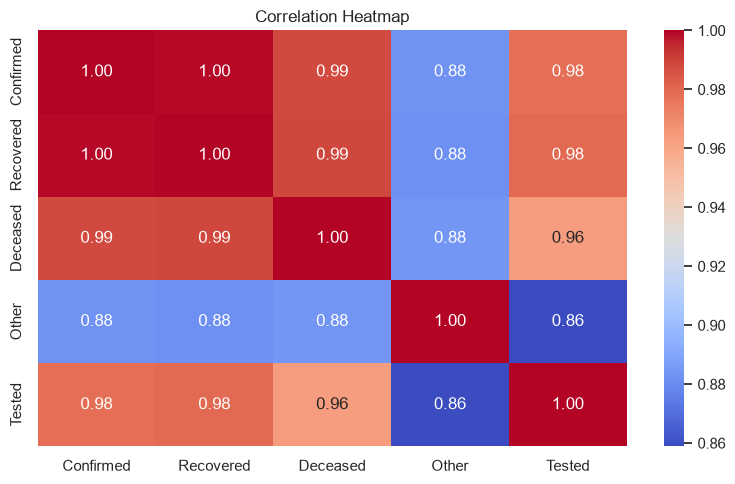

In [14]:
numeric_df = df.select_dtypes(include='number')
if numeric_df.shape[1] >= 2:
    plt.figure(figsize=(8, 5))
    sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
    plt.title('Correlation Heatmap')
    plt.tight_layout()
    plt.show()
else:
    print('Need at least two numerical columns.')

## 5. Bar chart – first categorical column

C:\Users\asus tuf a15\AppData\Local\Temp\ipykernel_29920\3810186483.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include='object').columns


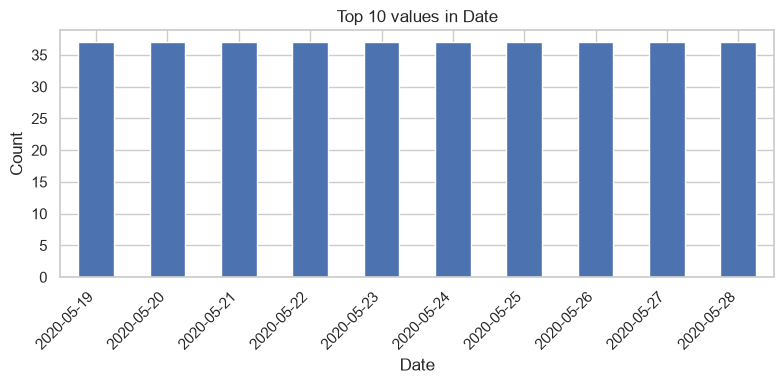

In [15]:
categorical_cols = df.select_dtypes(include='object').columns
if len(categorical_cols):
    col = categorical_cols[0]
    df[col].value_counts().head(10).plot(kind='bar', figsize=(8, 4))
    plt.title(f'Top 10 values in {col}')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
else:
    print('No categorical columns found.')

## 6. Save the dataset summary

In [16]:
results_dir = Path('results')
results_dir.mkdir(exist_ok=True)
df.describe(include='all').transpose().to_csv(results_dir / 'week1_results.csv')
print('Saved results/week1_results.csv')

Saved results/week1_results.csv


## 7. Observations

After running the notebook, note:
- How many rows and columns are present?
- Are there missing values?
- What does the histogram show?
- Which variables appear correlated?